# Assignment 4: One- and Two-Sample Tests
Authored by Kristian M. P. Dashnaw (344849) & Katrine B. Aamand (344848) <br>
Based on assignment 4 description (https://rbrooksdk.github.io/STA1_26/assignments/assignment_04_one_and_two_sample_tests/)

## Table of Contents

1. **Part 1 — One-sample decisions**
    - Mean sensor error
      - 1.1 Hypotheses and One-Sample $t$ Test
      - 1.2 Interpreting the $p$-Value, Decision, and Conclusion
      - 1.3 95% $t$ Interval, Test–Interval Duality, and Practical Importance
    - False-rejection probability
      - 1.4 One-Sided Hypotheses and Exact Binomial Test
      - 1.5 Wilson Interval and Why It Is Not the Exact Dual
      - 1.6 Type I and Type II Errors
2. **Part 2 — Independent coating processes**
    - 2.1 Independent vs. Paired Design, Group Summaries, and Boxplots
    - 2.2 Welch's Two-Sample $t$ Procedure
    - 2.3 Assumption Diagnostics and What Plots Cannot Establish
    - 2.4 Interval vs. Zero and the 8-Hour Threshold: Recommendation
3. **Part 3 — Paired building-energy measurements**
    - 3.1 Observational Unit, Genuine Pairs, and the Difference Column
    - 3.2 Paired Plot and Diagnostics of the Differences
    - 3.3 Paired $t$ Test and 95% Interval for $\mu_D$
    - 3.4 Why Pairing Matters, Interpretation, and Recommendation
4. **Part 4 — Comparing two independent proportions**
    - 4.1 Unit, Outcome, Populations, Assumptions, and Hypotheses
    - 4.2 Sample Proportions, Risk Difference, and 95% Interval
    - 4.3 Two-Proportion $z$ Test
    - 4.4 Random Sampling, Random Assignment, and Causal Claims
5. **Part 5 — AI-Use and Conclusion**
    - AI-Use Statement
    - Overall Conclusion

## Working Notes (DELETE BEFORE HANDIN)

**Statistical scope (from the assignment description):** Sessions 7–8 and Brooks, Chapters 7–8. Python throughout.

**How to present the work (from the assignment description):**

> For each analysis, state the population, parameter, observational unit, design, comparison order, hypotheses, and significance level before reporting the software result. Use plots and numerical diagnostics for assumptions. Report estimates and confidence intervals in engineering units.

**Analysis order (from the assignment description):**

> 1. Question, parameter, units, and comparison order.
> 2. Study design and assumptions.
> 3. Descriptive summaries and plots.
> 4. Effect estimate and confidence interval.
> 5. Hypotheses, statistic, $p$-value, and decision.
> 6. Practical importance, limitations, and conclusion.

**Theory and code at the oral exam (from the assignment description):**

> Be prepared to use examples from this assignment to explain hypotheses, one- and two-sided tests, test statistics, $p$-values, $\alpha$, Type I and II errors, power, one-sample $t$ and proportion tests, exact versus approximate procedures, test–interval duality, independent versus paired designs, Welch's test, paired tests as one-sample tests of differences, two-proportion comparisons, risk differences, effect uncertainty, practical importance, and the design requirements for generalisation and causation.
>
> You need not memorise code, but you must understand which parameter each function tests, how the design determines the method, and how the output supports the conclusion. AI use does not change this requirement.

In [ ]:
#Imports:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
from scipy.stats import t, ttest_rel, ttest_1samp, ttest_ind, shapiro, binomtest, norm, probplot
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

# Load the data files:
print("\nSensor_Calibration.csv, first 5 rows:")
sensorCalibrationData_unmodified = pd.read_csv('data/assignment03_sensor_calibration.csv', delimiter = ',')
display(sensorCalibrationData_unmodified.head(5))

print("\n\nAccess_Control.csv, first 5 rows:")
accessControlData_unmodified = pd.read_csv('data/assignment03_access_control.csv', delimiter = ',')
display(accessControlData_unmodified.head(5))

print("\n\nCoating_Durability.csv, first 5 rows:")
coatingDurabilityData_unmodified = pd.read_csv('data/assignment04_coating_durability.csv', delimiter = ',')
display(coatingDurabilityData_unmodified.head(5))

print("\n\nEnergy_Retrofit.csv, first 5 rows:")
energyRetrofitData_unmodified = pd.read_csv('data/assignment04_energy_retrofit.csv', delimiter = ',')
display(energyRetrofitData_unmodified.head(5))


Sensor_Calibration.csv, first 5 rows:


,sensor_id,calibration_error_c
0,1,0.334
1,2,0.383
2,3,1.644
3,4,0.627
4,5,0.615




Access_Control.csv, first 5 rows:


,attempt_id,false_reject
0,1,0
1,2,0
2,3,0
3,4,1
4,5,0




Coating_Durability.csv, first 5 rows:


,specimen_id,process,durability_h
0,1,standard,112.45
1,2,standard,109.55
2,3,standard,131.35
3,4,standard,130.96
4,5,standard,110.15




Energy_Retrofit.csv, first 5 rows:


,building_id,before_kwh_day,after_kwh_day
0,1,91.57,87.75
1,2,95.33,90.14
2,3,85.20,85.61
3,4,75.96,64.30
4,5,85.33,81.90


<br><br><br>

---

<br>

## Part 1: One-sample decisions

<br><br>

<br>

### Mean sensor error

Use [assignment03_sensor_calibration.csv](./data/assignment03_sensor_calibration.csv). The engineering team asks whether population mean calibration error differs from zero; errors with absolute mean below $0.50\ ^\circ\mathrm C$ are regarded as small in practice.

<br><br>
#### 1.1 State $H_0$, the two-sided $H_1$, and $\alpha=0.05$. Use a one-sample $t$ procedure and report the sample mean, test statistic, degrees of freedom, and two-sided $p$-value.

Authored by: Katrine
<br> <br>


##### Step 1: Question, parameter, units and comparison order
||                                                                                                                                                                                                                                                                                                                                                                  |
|:------:|:----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------:|
| Question |                                                                                                                                                   Does the population mean calibration error differ from 0°C?                                                                                                                                                    |
| Population |                                                                                                                                           All sensors of this type, under the conditions in which they were calibrated                                                                                                                                           |
| Parameter | The parameter is $\mu$, the population mean calibration error i °C. A sensor's calibration error is its reading minus the reference temperature, so a positive error means that the sensor reads too high, and a negative error means it reads too low. We cannot know $\mu$ itself, since the sample only gives us an estimate of it, the sample mean $\bar{x}$ |
| Comparison order |                                                                                                   We compare $\mu$ with the null value $\mu_0 = 0$ °C in both directions, since a sensor that reads too high is as problematic as a sensor that reads too low.                                                                                                   |
| Units |                                                                                                                                                                                °C                                                                                                                                                                                |



##### Step 2: Design and assumptions

It is a single-sample design of $n = 64$ sensors, where each sensor has one recorded calibration error. The sample mean is compared with the fixed null value $\mu_0 = 0$ °C.
The data description does not state how the senors were selected or measured, so the points below are assumptions rather than facts.

For the one-sample $t-test$ to be trustworthy, we assume that:
1. Independence, the calibration error of one sensor does not affect or depend on the error of another
2. Representative sample, the 64 sensors are representative of all sensors of this type, so the conclusion can be generalised to the population.
3. Approximate normality: the calibration errors are roughly normally distributed without strong skewdness or influential outliers. With $n = 64$, the central limit theorem also makes the sample mean approximately normal. We assess this with a histogram, a QQ-plot and a Shapio-Wilk test in step 3.
4. Valid measurements, meaning that the reference temperature is correct, and all sensors were calibrated under comparable conditions.

Assumptions 1, 2 and 4 concern how the data were collected and cannot be established from plots. Only assumption 3 can be assessed from the data.

For our significance level we use $\alpha = 0.05$, as specified in the task.

##### Step 3: Descriptive summaries and plots.

We compute the sample size $n$, the sample mean $\bar{x}$, the sample standard deviation $s$ and the estimated standard error $SE = s/\sqrt{n}$. To assess assumption 3 (approximate normality), we plot a histogram with a fitted normal curve and a normal QQ-plot, and run a Shapiro–Wilk test.

n = 64, mean = 0.188 °C, s = 0.626 °C, SE = 0.078 °C
Shapiro-Wilk: W = 0.990, p = 0.874


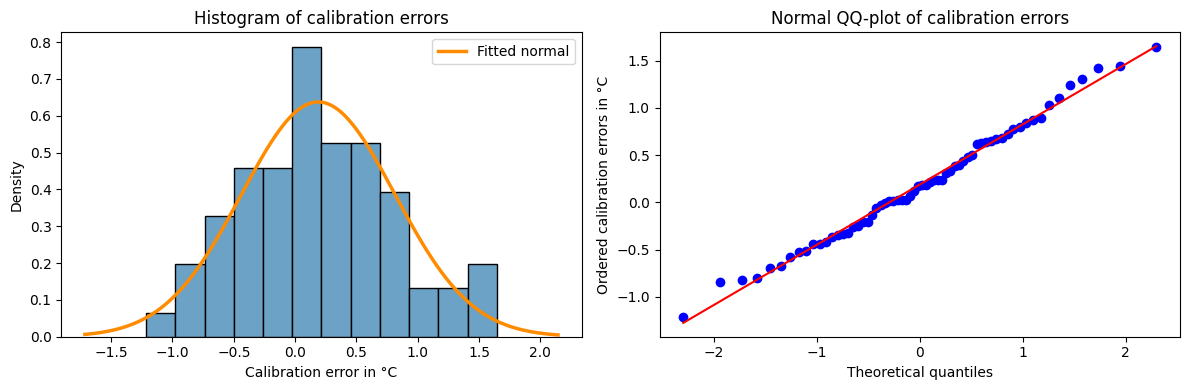

In [13]:
# Katrine

# Descriptive summaries and normality diagnostics for the calibration errors
errors = sensorCalibrationData_unmodified["calibration_error_c"]

n = len(errors)
x_bar = errors.mean()
s = errors.std(ddof=1)
se = s / np.sqrt(n)
print(f"n = {n}, mean = {x_bar:.3f} °C, s = {s:.3f} °C, SE = {se:.3f} °C")

shapiro_result = shapiro(errors)
print(f"Shapiro-Wilk: W = {shapiro_result.statistic:.3f}, p = {shapiro_result.pvalue:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

xs = np.linspace(errors.min() - 0.5, errors.max() + 0.5, 200)
axes[0].hist(errors, bins=12, density=True, color="#6CA2C6", edgecolor="black")
axes[0].plot(xs, norm.pdf(xs, loc=x_bar, scale=s), color="#FF8C00", linewidth=2.5, label="Fitted normal")
axes[0].set(title="Histogram of calibration errors", xlabel="Calibration error in °C", ylabel="Density")
axes[0].legend()

probplot(errors, dist="norm", plot=axes[1])
axes[1].set(title="Normal QQ-plot of calibration errors", xlabel="Theoretical quantiles", ylabel="Ordered calibration errors in °C")

plt.tight_layout()
plt.show()

##### Findings

Summary statistics: the 64 sensors have a sample mean calibration of $\bar{x} = 0.188$ °C, so on average the sensors in the sample reads 0.188°C too high. The sample standard deviation is $s = 0.626$ °C, which shows that individual sensors vary considerably, from around -1.2°C to 1.6°C. The estimated standard error is 0.078°C, which describes how much the sample mean would typically vary between repeated samples of 64 sensors.

In the histogram we see that the distribution has two peaks, one slightly above 0°C and one slighty above 1.5°C, but is roughly symmetric. The fitted normal curve follows the bars reasonably well and there are no isolated values far from the rest.

The QQ-plot shows that the points lie close to the straight line across the entire range, with small deviations at the ends. The is no systematic curvature that would indicate strong skew or heavy tails.

Shapiro-Wilk: $W=0.990$, which is close to 1 with $p=0.874$. Since $p > 0.05$, the test gives no evidence against normality. This does not prove that the errors are normally distributed, but together with the plots it indicates that a normal model is adequate.

The conclusion on assumption 3 is that the calibration errors appear approximately normal without strong skew or outliers, so the one-sample t-test is reasonable for these data.

##### Step 4: Effect estimate and confidence interval

The estimated effect is: $\bar{x} - \mu_0 = 0.188 - 0 = 0.188$ °C. Telling us that on average the sampled sensors read about 0.19°C too high.

The confidence interval is evaluated in 1.3.

##### Step 5: Hypothesis, statistic, p-value and decision
<br>

###### Hypotheses
We let μ denote the population mean calibration error, in °C, of all sensors of this type under the calibration conditions. A value of 0°C means that the sensors are correct on average.

$H_0: \mu = 0$ °C (no systematic calibration error)

$H_1: \mu \neq 0$ °C (a systematic calibration error in either direction)
<br><br>
###### Significance level
We use $\alpha = 0.05$, as specified in the task
<br><br>
###### Test statistics
Since the population standard deviation is unknown and estimated by $s$, we use the one-sample $t$ statistic:

$$t = \frac{\bar{x} - \mu_0}{s/\sqrt{n}}, \qquad df = n - 1$$

Under $H_0$ and the assumptions from step 2, this statistics hollows a $t$ distribution with $n - 1$ degrees of freedom.

In [14]:
# One-sample t-test: test statistic, degrees of freedom and two-sided p-value
mu_0 = 0

# Manual computation from the formula
t_obs = (x_bar - mu_0) / se
dof = n - 1
p_value = 2 * t.sf(abs(t_obs), dof)
print(f"Manual: t = {t_obs:.3f}, df = {dof}, p = {p_value:.4f}")

# Verification with SciPy
res = ttest_1samp(errors, popmean=mu_0, alternative="two-sided")
print(f"SciPy:  t = {res.statistic:.3f}, df = {res.df}, p = {res.pvalue:.4f}")

Manual: t = 2.407, df = 63, p = 0.0190
SciPy:  t = 2.407, df = 63, p = 0.0190


###### Test result
For the 64 sensors, the sample mean calibration error is $\bar{x} = 0.188$ °C. The one-sample $t$ test gives a test statistic of $t = 2.407$ with $df = 63$ degrees of freedom and a two-sided $p$-value of $p = 0.019$. The manual computation and SciPy's `ttest_1samp` give identical results.

The test statistic means that the sample mean lies about 2.4 estimated standard errors above the null value of 0 °C. The interpretation of the $p$-value and the decision follow in 1.2.

<br><br>
#### 1.2 Interpret the $p$-value as a tail probability conditional on $H_0$ and the assumptions. State the decision and a contextual conclusion without treating the $p$-value as $P(H_0\mid\text{data})$.

##### Step 5 (continued): $p$-value and decision.

###### Interpretation of the $p$-value
If $H_0$ is true and the model assumptions hold, then in repeated samples of 64 sensors, a test statistic at least as far from 0 as $t = 2.407$, in either direction, would occur in approximately 1.9% of the samples.

The $p$-value is calculated under the assumption that $H_0$ is true. The $p$-value does not tell us the probability that $H_0$ is true. It was calculated by assuming that $H_0$ is true, so it only tells us how surprising our data would be in that case.

###### Decision
Since $p = 0.019 \leq \alpha = 0.05$, we reject $H_0$.

###### Conclusion
The data provide evidence that the population mean calibration error of this type of sensor differs from 0 °C. Since $\bar{x} = 0.188$ °C is positive, the sensors appear on average to read too high, by an estimated 0.19 °C. The test does not tell us whether this error is large enough to matter in practice. This is assessed in 1.3 by comparing the confidence interval with the practical limit of 0.50 °C. The conclusion also relies on the assumptions from Step 2, in particular independence and a representative sample.

<br><br>
#### 1.3 Reuse or reconstruct the 95% $t$ interval and explain its duality with this two-sided test. Compare it with the practical limits and distinguish statistical significance from practical importance.

##### Step 4 (continued): Confidence interval.

We reuse the one-sample $t$ procedure from 1.1. The 95% $t$ interval for $\mu$ is

$$\bar{x} \pm t^* \cdot \frac{s}{\sqrt{n}}, \qquad t^* = t_{0.975,\ n-1}$$

where $t^*$ is the critical value that leaves 2.5% in each tail of the $t$ distribution with $n - 1 = 63$ degrees of freedom.

In [15]:
# Katrine

# 95% t-interval for the population mean calibration error
t_star = t.ppf(0.975, df=dof)
margin_of_error = t_star * se
ci_low, ci_high = x_bar - margin_of_error, x_bar + margin_of_error
print(f"Manual: t* = {t_star:.3f}, margin of error = {margin_of_error:.3f} °C, 95% CI = [{ci_low:.3f}, {ci_high:.3f}] °C")

# Verification by reusing the t-test result from 1.1
ci_scipy = res.confidence_interval(confidence_level=0.95)
print(f"SciPy:  95% CI = [{ci_scipy.low:.3f}, {ci_scipy.high:.3f}] °C")

Manual: t* = 1.998, margin of error = 0.156 °C, 95% CI = [0.032, 0.345] °C
SciPy:  95% CI = [0.032, 0.345] °C


###### Interpretation of the interval
The 95% confidence interval for $\mu$ is $[0.032,\ 0.345]$ °C. It is estimated from the sample mean, the standard error and the critical value $t^*$:

$$0.188 \pm 1.998 \cdot 0.078 \approx [0.032,\ 0.345] \text{ °C}$$

The interval gives the plausible values for the population mean calibration error $\mu$. This means that, on average, sensors of this type plausibly read between about 0.03 °C and 0.35 °C too high. The 95% refers to the method: if we repeated the study many times, about 95% of the intervals would contain $\mu$.

###### Duality with the two-sided test
The null value $\mu_0 = 0$ °C lies outside the interval. This agrees with 1.2, where we rejected $H_0$. It is not extra evidence, but the same result seen from another angle. The test and the interval are built from the same ingredients ($\bar{x}$, $SE$ and $t^*$), so a two-sided test at $\alpha = 0.05$ rejects $H_0$ exactly when $\mu_0$ lies outside the 95% interval.

<br><br>

##### Step 6: Practical importance, limitations, and conclusion.
Statistical significance: Since 0 °C lies outside the interval, the data provide evidence of a systematic calibration error.

Practical importance: Errors with an absolute mean below 0.50 °C are regarded as small in practice. The whole interval lies between −0.50 °C and 0.50 °C, and even the largest plausible value, 0.345 °C, is below 0.50 °C. The error is therefore statistically significant, but small in practice.

Limitations: The conclusion relies on the assumptions from Step 2, in particular that the sensors are independent and representative of all sensors of this type.

<br><br>

### False-rejection probability

Use [assignment03_access_control.csv](./data/assignment03_access_control.csv). The pre-specified question is whether the false-rejection probability exceeds the 5% target.

<br>

#### 1.4 State the one-sided hypotheses. Perform an exact binomial test and report $\hat p$, the $p$-value, decision, and conclusion.
Authored by: Kristian

##### Step 1: Question, parameter, units, and comparison order.

|                  |                                                                                                                                                                                                                                                                                                                   |
|:----------------:|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------:|
|     Question     |                                                                                                                            Does the false-rejection probability exceed the 5% target?                                                                                                                             |
|    Population    |                                                                          All the legitimate login/connection attempts under the test conditions, <br/>since we're interested in the false rejection rate - not the true rejection rate!                                                                           |
|    Parameter     | The parameter for this study is $p$, the true probability <br/> that a legitimate login attempt is falsely rejected.<br/>We can't know $p$ itself, since our sample only <br/>gives us access to estimates of this value.<br/>The unit associated with the probability is either percentage or percentage points. |
| Comparison order |                                                                          This is tied to the hypothesis. We compare p with the target $p_0 = 0.05$,<br/>in the upper direction - since our concern is having too many false rejections.                                                                           |

<br>

##### Step 2: Study design and assumptions.

The sample contains 240 observational units, where a single observational unit is a login attempt.
Each attempt has a corresponding yes/no outcome (false rejected, or not).

Since we'll be using an exact binomial test, these assumptions must hold for the sample:
1. Each login attempt is independent
2. Each attempt has the same probability $p$ to be a false rejection.

From the chapter 7.4 in the course book, we are given that when X is the number of observations with the specified outcome among n independent Bernoulli trials, we get the following definition for the binomial distribution under a stable success probability $p$,

$X \sim \operatorname{Binomial}(n, p), \qquad \hat{p} = \frac{X}{n}.$

We'll compute this in code below

<br>

##### Step 3: Descriptive summaries and plots.
For this, we'll stick with the exact binomial test requested in this task, and compute in the code block below:

In [16]:
# Kristian
p_0 = 0.05

n_connection_attempts = accessControlData_unmodified["false_reject"].count()
print(f"Number of connection attempts,             n = {n_connection_attempts}")

x_false_rejections = int(accessControlData_unmodified["false_reject"].to_numpy().sum())
print(f"Number of false rejections,                x = {x_false_rejections}")

p_hat_false_rejections = x_false_rejections / n_connection_attempts
print(f"Observed false rejection probability,   phat = {p_hat_false_rejections:.4f}\n")

Number of connection attempts,             n = 240
Number of false rejections,                x = 20
Observed false rejection probability,   phat = 0.0833



We see that the false rejection rate is $0.0833 \approx 8.3%$ (20/240), which is higher than the expected 12/240 should a 5% false rejection rate be upheld.

<br>

##### Step 4: Effect estimate and confidence interval.
**Effect:** The effect is estimated at $\hat{p} - p_0 = 0.083 - 0.050 = 0.033$, which is approx 3.3 percentage points **above** the 5% target.

**Confidence Interval:** Not evaluated here in 1.4. Please look at 1.5 for this.

<br>

##### Step 5. Hypotheses, statistic, $p$-value, and decision.

###### Hypothesis
Since we wish to identify the false-rejection probability that exceeds the 5% target, we can define a one-sided (upper-tailed) hypothesis:

$H_0 : p \leq 0.05$

$H_1 : p > 0.05$

Here $H_0$ states that the false rejection probability $p$ of the system under test conditions is at most 5%, while $H_1$ states that it exceeds 5%. This concerns our population parameter $p$, not the sample.

|                  | H_0 is True                                                       | H_1 is True                                                  |
|:----------------:|-------------------------------------------------------------------|--------------------------------------------------------------|
|  Fail to Reject  | True Negative<br/>Probability: 1 - alpha<br>Correct non-rejection | Type II Error<br/>Probability: beta                          |
|      Reject      | Type I Error<br/>Probability: alpha                               | True Positive<br/>Probability: 1 - beta<br>Correct detection |

<br>

###### Significance level
Pr. Definition 7.5 from the course book, we shall decide upon an acceptable significance level ($\alpha$). This is the chosen upper bound on the probability of rejecting $H_0$ when the null hypothesis is true.

Since this is not a safety-critical system, we settle for 0.05, so that:

$\alpha = 0.05$

<br>

###### Test statistic
This is the count ($X$) of false rejections.

We observed $x = 20$ false rejections in the sample.

<br>

In [17]:
binom_test_false_rejections = binomtest(x_false_rejections, n=n_connection_attempts, p=p_0, alternative="greater")
print(f"{binom_test_false_rejections}")

BinomTestResult(k=20, n=240, alternative='greater', statistic=0.08333333333333333, pvalue=0.018485562994802782)


###### p-value
This is defined as the probability that the number of false rejections are equal to (or higher than) the observed number of false rejections, given that our hypothesis that max. false rejection rate of 5% is true.

Our exact binomial test showed that:

$P(X ≥ 20 | p = 0.05) = 0.018$

<br>

###### Decision
Since p-value $\leq \alpha$ we reject $H_0$. This is derived by the **standard decision rule** in chapter 7.2 in the course book.

$0.018 \leq 0.05$ is true

<br>

##### Step 6. Practical importance, limitations, and conclusion.
At $\alpha = 0.05$ we reject $H_0$. The data indicates that the false rejection probability under these test conditions exceeds the 5% target, which we estimated at 8.3%.

This is 3.3 percentage points above target. The consequence is that more users, than currently acceptable, are potentially wrongly rejected during their login/connection attempts.

This conclusion is limited by the test conditions and the assumption that all login/connection attempts are independent.

<br><br>
#### 1.5 Use the Wilson interval as an estimate of plausible values, while explaining why a two-sided Wilson interval is not the exact dual of a one-sided exact test.
Authored by: Kristian

##### Step 1: Question, parameter, units, and comparison order.
Same as for 1.4

<br>

##### Step 2: Study design and assumptions.
The sample contains 240 observational units, where a single observational unit is a login attempt.  Each attempt has a corresponding yes/no outcome (false rejected, or not).

Since we'll be using the wilson interval, these assumptions must hold for the sample, as stated in the Course Book chapter 7.4 (p. 118):
1. Each login attempt is independent
2. Each attempt has the same probability $p$ to be a false rejection.
3. Normal approximation must be adequate

For item 3, the course book chapter 6.4 specifically states that: "Conditions such as $n\hat{p} \geq 10$ and $n(1 - \hat{p}) \geq 10$ are useful diagnostics, not universal guarantees."

As such, we'll be using these diagnostics as indicators for sufficient approximation quality.

<br>

##### Step 3: Descriptive summaries and plots.
We'll calculate the wilson endpoints below, and evaluate the approximation quality.

In [18]:
# Kristian
wilson_false_rejections_95_low, wilson_false_rejections_95_high = proportion_confint(x_false_rejections, n_connection_attempts, alpha=0.05, method="wilson")
print(f"Wilson interval: [{wilson_false_rejections_95_low:.3f}, {wilson_false_rejections_95_high:.3f}]")

print(f"n * p_hat      = {p_hat_false_rejections*n_connection_attempts}")
print(f"n(1 - p_hat)   = {n_connection_attempts*(1-p_hat_false_rejections)}")

Wilson interval: [0.055, 0.125]
n * p_hat      = 20.0
n(1 - p_hat)   = 220.0


Since both our conditions are larger than 10, the normal approximation behind the wilson interval appears adequate.

<br>

##### Step 4: Effect estimate and confidence interval.
**Confidence Interval:** We see that the 95% wilson interval for $p$ is $[0.055, 0.125]$. This means that the plausible values for the false-rejection probability, under these test conditions, are between 5.5% and 12.5%. This applying to about 95% of the procedures (i.e. 95% of all intervals constructed this way, using repeated samples).

**Effect:** Compared to 1.4, which found a 3.3 percentage point excess in false rejection rate probability, we here in 1.5 find that the excess above the 5% target is plausibly between 0.5 $(5.5-5.0)$ and 7.5 $(12.5-5.0)$ percentage points.

<br>

##### Step 5. Hypotheses, statistic, $p$-value, and decision.

###### Hypothesis, Significance level, Test statistic, $p$-value & decision
Explained in 1.4

<br>

###### Duality explanation
Theorem 7.3 from the course book (p. 119) states that for two-sided tests, the test and interval are dual, when they come from the same method. In which case $H_0$ is rejected exactly when $p_0$ lies outside the corresponding interval.
This also states that the matching pair for a wilson score interval is a score test (z-score). In 1.4 we used an exact binomial test - which is not z score based. Our hypothesis also builds a one-sided upper tail, placing all our 5% significance level ($\alpha$) there. The wilson interval, on the other hand, is two-sided, placing 2.5% at each the lower and upper tails.

**Comparison with the decision in 1.4:** Considering the above, we still see in 1.5 that the lower bound of the wilson interval is 0.5 percentage points above our 5% target. In this case the wilson confidence interval supports our exact binomial decision. Had our data been closer to the boundary, these two methods could have shown different answers conflicting with each other.

<br>

##### Step 6. Practical importance, limitations, and conclusion.
Building on the conclusion from 1.4, we see that the exact binomial test in 1.4 gives evidence that $p$ exceeds 5%, and the Wilson interval computed in 1.5 shows the size of the excess with its uncertainty, plausibly between 0.5 and 7.5 percentage points.

This conclusion is limited by the test conditions and the assumption that all login/connection attempts are independent.

<br><br>
#### 1.6 Describe Type I and Type II errors in one of the two one-sample studies and state an operational consequence of each.
Authored by: Kristian

This description builds upon the one-sample study described in 1.4 and 1.5. Our hypothesis was that $H_0 : p \leq 0.05$, so the alternative upper-tail was defined as $H_1 : p > 0.05$. Only one of these can be true, at the same time.

Visually, this can be presented as:

|                | H_0 is True                                                       | H_1 is True                                                  |
|----------------|-------------------------------------------------------------------|--------------------------------------------------------------|
| Fail to Reject | True Negative<br/>Probability: 1 - alpha<br>Correct non-rejection | Type II Error<br/>Probability: beta                          |
| Reject         | Type I Error<br/>Probability: alpha                               | True Positive<br/>Probability: 1 - beta<br>Correct detection |

<br>

**Meaning of type I vs type II errors:**

Type I error : We conclude that the false rejection rate exceeds the 5% threshold - but in reality it actually meets this target threshold (i.e. false alarm).
Type II error: We don't find any evidence showing that the false rejection rate exceeds the 5% threshold - but in reality the rate actually exceeds these 5% (i.e. missed detection).

In task 1.4 and 1.5 we tested $H_0$, and rejected it. In this, the only error we could have made was the type I errors - which given $H_0$ is true, would be produced at most 5% of the time. A type II error was not possible for this decision, but had we failed to reject $H_0$ this could have become a risk if in reality $H_1$ is true while $H_0$ is false.

**Operational consequences:**

Since we rejected $H_0$ in 1.4 and 1.5, we have a case where we are dealing with either a type I error (given $H_0$ in reality is true), or a True Positive (i.e. $H_1$ is true in reality). The data alone can't tell us which of these is true in reality. If $H_0$ is true in reality (so our rejection of $H_0$ was a type I error), the operational consequence will be that we spend time recalibrating the authentication infrastructure - and in the worst case we could calibrate this based on wrong conclusions causing the system to accept more unauthorized connection attempts.

The operational consequences of a type II error would, on the other hand, be that the system stays operational with a too high false rejection rate, causing more legitimate connection attempts to be rejected - which of course could cause frustrated users, more work for our staff and similar consequences.

<br><br><br>

---

<br>

## Part 2: Independent coating processes

The file [assignment04_coating_durability.csv](./data/assignment04_coating_durability.csv) contains independent specimens from a standard and modified coating process. Let

$$
\delta=\mu_{\text{modified}}-\mu_{\text{standard}},
$$

measured in durability hours. An increase of at least 8 hours is considered practically important.

<br><br>
### 2.1 Explain why the samples are independent rather than paired. Report group $n$, mean, sample standard deviation, and boxplots.

Authored by: Katrine
<br><br>


##### Step 1: Question, parameter, units and comparison order.

|                     |                                                                                                                                                                                 |
|:-------------------:|:-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------:|
|      Question       |                                 Does the mean durability differ between the modified and the standard coating process, and if so, by how much?                                  |
| Observational unit  |                                                                                A single specimen                                                                                |
|     Populations     |                            Two populations: all specimens coated with the standard process,<br/>and all specimens coated with the modified process.                             |
|      Parameter      |                      $\delta = \mu_{\text{modified}} - \mu_{\text{standard}}$,<br/>the difference between the two population mean durabilities, in hours.                       |
|  Comparison order   | Modified minus standard. A positive $\delta$ means that the modified process lasts longer on average,<br/>and a negative $\delta$ means that the standard process lasts longer. |
|        Units        |                                                                                      Hours                                                                                      |
| Practical threshold |                                            An increase of at least 8 hours ($\delta \geq 8$ h) is considered practically important.                                             |

##### Step 2: Study design and ssumptions

##### Why the samples are independent rather than paired
The data contain 48 specimens from the modified process and 44 specimens from the standard proces. Each specimen has their own id, and only appers once, with one coating process and one durability measurement. If the samples where paired, then they would have the same sample size, where every pair contributes one observation to each group. The task description also describes the data as independent specimens. The two samples are therefore independent rather that paired.

##### Assumptions
For the comparison of the two means to be trustworthy we assume that:

1. Independence within each sample: The durability of one specimen does not affect or depend on the durability of another specimen in the same group.
2. Independence between the samples: No specimen appears in both groups, and the specimens are not matched across groups.
3. Representative samples: Each sample is representative of all specimens coated with that process.
4. Approximate normality in each group: Durability within each group is roughly normally distributed without strong skew or influential outliers. With $n = 44$ and $n = 48$, the central limit theorem also makes each sample mean approximately normal. This is assessed in 2.3.
5. Comparable measurement: Both groups were tested under the same conditions and with the same equipment. Otherwise, a difference could be caused by the test rather than the coating.

Assumptions 1, 2, 3 and 5 concern how the data were collected and cannot be established from plots.

Significance level: We use the conventional $\alpha = 0.05$.


##### Step 3: Descriptive summaries and plots.

For each process, we compute the group size $n$, the sample mean $\bar{x}$ and the sample standard deviation $s$, and we compare the two groups with boxplots.

,n,mean,s
process,,,
modified,48,132.49,22.19
standard,44,117.29,15.75


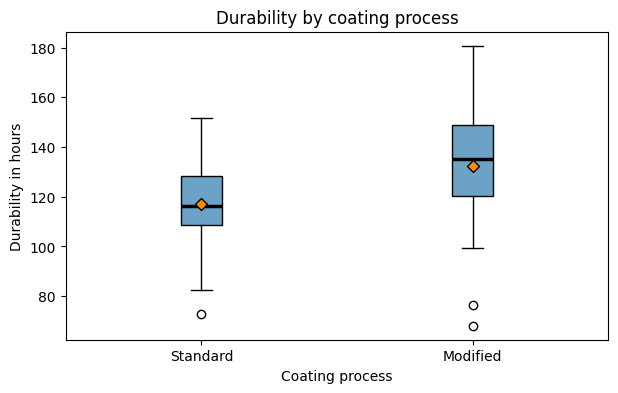

In [19]:
# Group summaries and boxplots of durability for each coating process
coating = coatingDurabilityData_unmodified

summary = coating.groupby("process")["durability_h"].agg(n="count", mean="mean", s="std")
display(summary.round(2))

standard = coating.loc[coating["process"] == "standard", "durability_h"]
modified = coating.loc[coating["process"] == "modified", "durability_h"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([standard, modified], showmeans=True, patch_artist=True, boxprops=dict(facecolor="#6CA2C6", edgecolor="black"), medianprops=dict(color="black", linewidth=2.5), meanprops=dict(marker="D", markerfacecolor="#FF8C00", markeredgecolor="black"))
ax.set_xticks([1, 2], ["Standard", "Modified"])
ax.set(title="Durability by coating process", xlabel="Coating process", ylabel="Durability in hours")
plt.show()

###### Findings
Group summaries: The modified proces has $n = 48$ specimens with a sample mean of $\bar{x} = 132.49$ hours and a sample standard deviation of $s = 22.19$ hours. The standard process has $n = 44$ specimens with a sample mean of $\bar{x} = 117.29$ hours and a sample standard deviation of $s = 15.75$ hours

Center: The modified process has both the higher median (about 135 hours) and the higher mean. In both groups the mean is close to the median. In the modified group the mean is slightly lower that the median, which is consistent with the two low outliers pulling the mean down.

Spread: The modified process varies more that the standard process, this is seen in the larger standard deviation, 22.19 hours vs. 15.75 hours, the taller box and the longer whiskers.

Outliers: The standard process sample group has one low outlier, about 75 hours, while the modified sample group has two low outliers, around 70 and 78 hours. These will be further examined in 2.3.

<br><br>
### 2.2 State two-sided hypotheses about $\delta$. Use Welch's two-sample $t$ procedure and report the estimated difference, 95% confidence interval, statistic, approximate degrees of freedom, and $p$-value. Do not use a preliminary variance test to switch automatically between pooled and Welch procedures.

Authored by: Katrine

##### Step 4: Effect estimate and confidence interval.
Since the two samples are assumed independent we can compare their means with Welsch's two-sample $t$ procedure. Welch lets each sample group keep their own standard deviation, instead of assuming that the populations have the same spread. This matters here, because the two sample standard deviations differ. Welch gives reliable results whether the population variance are equal or not, so we can use it directly.

The estimated difference is: $\hat{\delta} = \bar{x}_{\text{modified}} - \bar{x}_{\text{standard}}$, and its standard error combines the uncertainty from both groups:
$$SE = \sqrt{\frac{s^2_{\text{modified}}}{n_{\text{modified}}} + \frac{s^2_{\text{standard}}}{n_{\text{standard}}}}$$

The 95% confidence interval is $\hat{\delta} \pm t^* \cdot SE$, where $t^*$ is the 97.5% quantile of the $t$ distribution with Welch–Satterthwaite degrees of freedom $\nu$.

<br><br>

##### Step 5: Hypothesis, statistic, $p$-value and decision
<br><br>
###### Hypothesis
$H_0: \delta = 0$ h (no difference in population mean durability)

$H_1: \delta \neq 0$ h (a difference in either direction)
<br><br>
###### Significance level
We use $\alpha = 0.05$.
<br><br>
###### Test statistic
$$t = \frac{\hat{\delta} - 0}{SE}$$

Under $H_0$ and the assumptions from step 2, $t$ follows an approximate $t$ distrbution with $\nu$ degrees of freedom.

In [20]:
# Welch's two-sample t procedure for delta = mu_modified - mu_standard
n_mod, n_std = len(modified), len(standard)
xbar_mod, xbar_std = modified.mean(), standard.mean()
s_mod, s_std = modified.std(ddof=1), standard.std(ddof=1)

# Signal: the estimated difference. Noise: its standard error
delta_hat = xbar_mod - xbar_std
se_diff = np.sqrt(s_mod**2 / n_mod + s_std**2 / n_std)

# Welch-Satterthwaite degrees of freedom
nu = (s_mod**2 / n_mod + s_std**2 / n_std)**2 / ((s_mod**2 / n_mod)**2 / (n_mod - 1) + (s_std**2 / n_std)**2 / (n_std - 1))

# Test statistic, two-sided p-value and 95% confidence interval
t_obs_welch = (delta_hat - 0) / se_diff
p_welch = 2 * t.sf(abs(t_obs_welch), nu)
t_star_welch = t.ppf(0.975, nu)
ci_low_welch, ci_high_welch = delta_hat - t_star_welch * se_diff, delta_hat + t_star_welch * se_diff
print(f"Manual: difference = {delta_hat:.2f} h, SE = {se_diff:.3f} h, t = {t_obs_welch:.3f}, df = {nu:.2f}, p = {p_welch:.6f}")
print(f"        95% CI = [{ci_low_welch:.2f}, {ci_high_welch:.2f}] h")

# Verification with SciPy (equal_var=False gives Welch's procedure)
res_welch = ttest_ind(modified, standard, equal_var=False, alternative="two-sided")
ci_welch = res_welch.confidence_interval(confidence_level=0.95)
print(f"SciPy:  t = {res_welch.statistic:.3f}, df = {res_welch.df:.2f}, p = {res_welch.pvalue:.6f}")
print(f"        95% CI = [{ci_welch.low:.2f}, {ci_welch.high:.2f}] h")

Manual: difference = 15.20 h, SE = 3.987 h, t = 3.812, df = 84.84, p = 0.000260
        95% CI = [7.27, 23.13] h
SciPy:  t = 3.812, df = 84.84, p = 0.000260
        95% CI = [7.27, 23.13] h


###### Findings
Effect estimate, the estimated difference is $\hat{\delta} = 132.49 - 117.29 = 15.20$ hours. In the samples, the modified specimens lasted on average 15.2 hours longer than the standard specimens.

Confidence intercal, the 95% confidence interval for $\delta$ is $[7.27,\ 23.13]$ hours. These are the plausible values for the true difference in mean durability.

Test statistics: $t = 3.812$ with $\nu = 84.84$ approximate degrees of freedom. The estimated difference is about 3.8 times larger than its standard error.

$p$-value: The two-sided $p$-value is $p = 0.00026$. If there were no difference in population mean durability and the assumptions hold, a test statistic at least as far from 0 as 3.812 in either direction, would occur in about 0,03% of repeated samples.

###### Decision
Since $p = 0.00026 \leq \alpha = 0.05$, we reject $H_0$. The data provide evidence that the mean durability differs between the two processes, with the modified process lasting longer. The interval excludes 0, which agrees with the test(test-interval duality). Whether the difference is large enough to matter in practice is assessed in 2.4.

<br><br>
### 2.3 Assess independence from the design and distribution shape and unusual observations from group plots or residual diagnostics. State what the plots cannot establish.

Authored by: Katrine

##### Assumption diagnostics

Independence cannot be assesed from the data. It follows from the design: each specimen recived only one coating process and was measured once, and the tast description descrives the sepcimens as independent.

We assess the distribution shape and unusual observations separately for each group, because the normality assumption is about each population around its own mean, combining the two groups in one plot could create an apperent non-normality, since the two groups have different means.

Standard: Shapiro-Wilk W = 0.977, p = 0.523
Modified: Shapiro-Wilk W = 0.970, p = 0.247


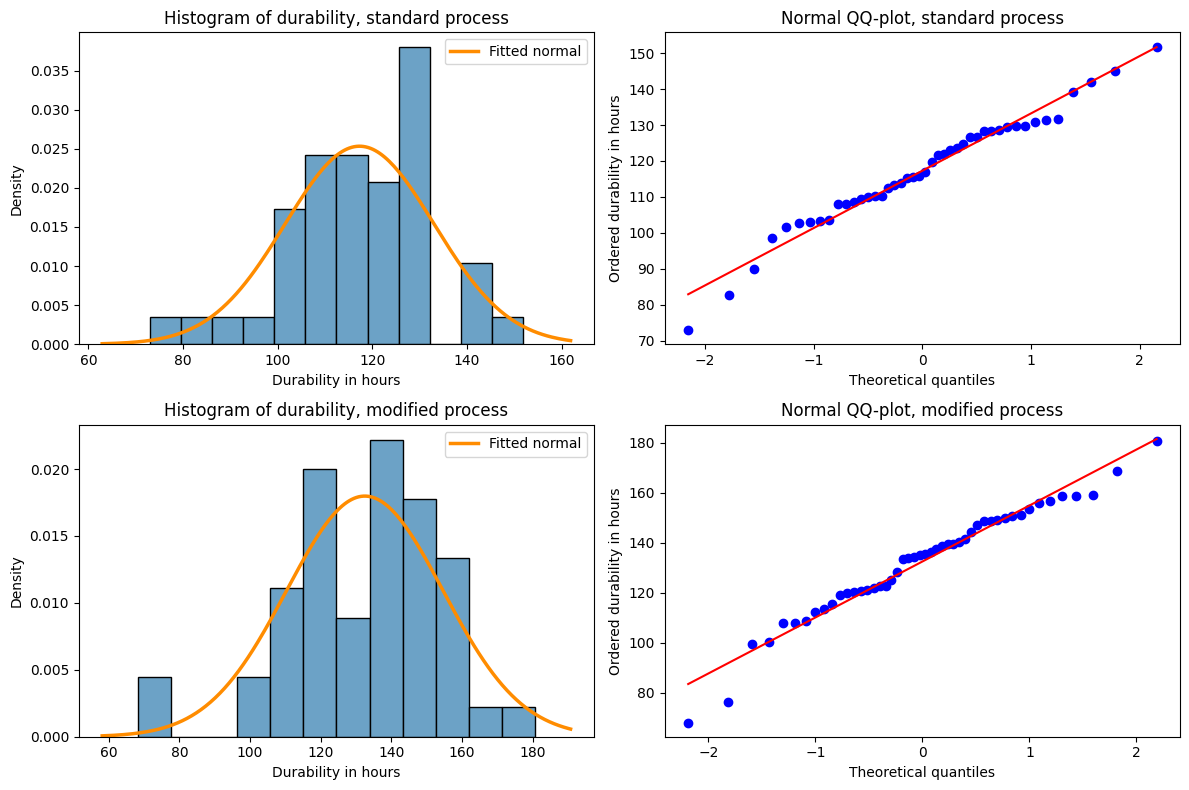

In [21]:
# Normality diagnostics for each coating process: histograms, QQ-plots and Shapiro-Wilk tests
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, (name, group) in enumerate([("Standard", standard), ("Modified", modified)]):
    xs = np.linspace(group.min() - 10, group.max() + 10, 200)
    axes[row, 0].hist(group, bins=12, density=True, color="#6CA2C6", edgecolor="black")
    axes[row, 0].plot(xs, norm.pdf(xs, loc=group.mean(), scale=group.std(ddof=1)), color="#FF8C00", linewidth=2.5, label="Fitted normal")
    axes[row, 0].set(title=f"Histogram of durability, {name.lower()} process", xlabel="Durability in hours", ylabel="Density")
    axes[row, 0].legend()

    probplot(group, dist="norm", plot=axes[row, 1])
    axes[row, 1].set(title=f"Normal QQ-plot, {name.lower()} process", xlabel="Theoretical quantiles", ylabel="Ordered durability in hours")

    shapiro_group = shapiro(group)
    print(f"{name}: Shapiro-Wilk W = {shapiro_group.statistic:.3f}, p = {shapiro_group.pvalue:.3f}")

plt.tight_layout()
plt.show()

###### Findings

Standard process: The histogram is roughly bell-shaped, apart from a tall bar around 125–130 hours and a gap around 135 hours, which is expected variation in a histogram of only 44 observations. In the QQ-plot, most points lie close to the line. The lowest values fall below the line, which indicates a slightly longer lower tail (mild left skew). The low outlier at about 73 hours is the lowest point.

Modified process: The histogram is more uneven, with peaks around 120 h and 140–160 h, but it is roughly bell-shaped overall. The two low outliers at about 68 h and 76 h are visible as a separate bar in the histogram and as the two lowest points below the line in the QQ-plot. Apart from the tails, the points follow the line closely. As seen in 2.1, this group has the larger spread.

Shapiro–Wilk: Standard: $W = 0.977$, $p = 0.523$. Modified: $W = 0.970$, $p = 0.247$. Both $W$ values are close to 1, and since both $p > 0.05$, the tests give no evidence against normality. This does not prove normality, but it agrees with the plots.

Conclusion on normality: Both groups show mild left skew and a few low outliers, but no strong departure from normality. With $n = 44$ and $n = 48$, the central limit theorem makes each sample mean approximately normal, so Welch's procedure is reasonable for these data.

Unusual observations: The three low outliers pull the group means down, most in the modified group, which has two of them. If anything, this makes the estimated difference slightly smaller, so the significant result is not driven by these observations.

<br><br>

###### What the plots cannot establish
The plots only show the shape of the observed data. They cannot establish that the specimens are independent, either within or between the groups, that each sample is representative of its process, or that both groups were tested under comparable conditions. These assumptions depend on how the specimens were selected and tested. The plots also cannot tell us why the three outliers are low, for example whether they are measurement errors or genuine early failures. Since there is no documented reason to remove them, they are kept in the analysis.

<br><br>
### 2.4 Compare the interval with both zero and the 8-hour practical threshold. Give a recommendation that reflects statistical uncertainty and practical importance.

Authored by: Katrine

##### Step 6: Practical importance, limitations, and conclusion.

Comparison with zero: The 95% confidence interval for $\delta$, $[7.27,\ 23.13]$ h, lies entirely above 0. This agrees with the Welch test in 2.2, where we rejected $H_0: \delta = 0$. The data therefore provide evidence that the modified process has a higher mean durability than the standard process.

Comparison with the 8-hour threshold: The practical threshold of 8 hours lies inside the interval, close to its lower end. Most of the plausible values are above 8 hours, and the estimate of 15.2 h is almost twice the threshold. However, the lower end of the interval (7.27 h) is slightly below 8 hours, so we cannot rule out that the true improvement is a little smaller than the practically important level.

Recommendation: The improvement is statistically significant and most likely practically important, so we recommend switching to the modified process. Since the lower end of the interval is just below 8 hours, the improvement should be confirmed, for example by testing more specimens, which would make the interval narrower, or by monitoring durability after the change. The recommendation also relies on the assumptions from Step 2, in particular that the specimens are representative and were tested under comparable conditions, and it should be weighed against any extra cost of the modified process.

<br><br><br>

---

<br>

## Part 3: Paired building-energy measurements

The file [assignment04_energy_retrofit.csv](./data/assignment04_energy_retrofit.csv) records energy use for the same 36 buildings before and after a control-system retrofit. Define the paired difference

$$
D=\text{before}-\text{after},
$$

so a positive value represents a reduction.

<br><br>
### 3.1 Explain the observational unit and why the rows form genuine pairs. Create the difference column and report its mean, standard deviation, and standard error.
Authored by: Kristian

<br>

We'll be following the expected 6-step analysis order defined in the assignment brief.

#### Step 1: Question, parameter, units, and comparison order.
|                    |                                                                                                                                                                                  |
|:------------------:|:--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------:|
|      Question      |                                                       Did the control-system retrofit change energy use, and by how much?                                                        |
| Observational Unit |                                              A single building, which includes data from before and after control-system retrofit.                                               |
|     Population     |                                            All buildings receiving this type of control-system retrofit, under comparable conditions.                                            |
|     Parameter      |                                        $\mu_D$ the population mean within-pair energy consumption difference (before - after) in kWh/day                                         |
|  Comparison order  | Compare mean difference in energy consumption before and after retrofit,<br/>such that $D_i = X_i - Y_i = \text{before} - \text{after}$,<br/>where positive value is a reduction |
|       Units        |                                                                                     kWh/day                                                                                      |

<br>

#### Step 2: Study design and assumptions.

A single sample of 36 buildings, with mean kWh/day energy consumption recorded for each prior to a control-system retrofit and after. The data is a complete pair-wise collection - there are no incomplete pairs.

Based on the provided description, we assume that:
1. Energy consumption recorded under each building id relates to the same building (i.e. data is pair-wise linked).
2. Mean energy consumption was recorded for each building, before and after, under similar conditions. Such that number of occupants, heating requirements, time of year, etc. is all comparable before and after retrofit. If the mean consumption before retrofit was collected in a cold month and the mean consumption after retrofit was collected in a warm month, that could invalidate this entire statistical analysis as recorded data would no longer be comparable under similar conditions.
3. The sample contains enough observations to make an accurate normal approximation of the differences (before - after).
4. Energy consumption of each building is independent of other buildings

Under these assumptions, the rows from the provided sample form genuine pairs because each row refers to a specific building that underwent control-system retrofit, where mean energy consumption before and after the retrofit was collected for this specific building.

**Significance Level**: We use the conventional significance of $\alpha = 0.05$.

<br>

#### Step 3: Descriptive summaries and plots.
The descriptive summary shall be conducted based on the process described in the course book chapter 8.3. p. 126, that includes:

1. Adding a column to the dataset, that shows the difference in energy consumption before and after retrofit, using: $D_i = X_i - Y_i$ kWh/day.

2. Compute the mean observed difference $\bar{d}$, from the difference column, using $(\sum{D_i}) / n$

3. Compute the observed sample standard deviation, using $s_D = \sqrt{\frac{1}{n-1} \sum_{i=1}^{n} (d_i - \bar{d})^2}$ (Defined in definition 1.10 in the course book)

4. Compute the estimated standard error, using $SE = s_D / \sqrt{n}$.

Plotting will be performed as part of 3.2, and will include checking the normality of the distribution. Ideally I would have done that as step 1 above, but since this assignment specifically asks for such plots in 3.2, I'll include it there instead - working under the assumption that the differences are approximately normal.

In [22]:
# Kristian
n_before = energyRetrofitData_unmodified["before_kwh_day"].count()
n_after = energyRetrofitData_unmodified["after_kwh_day"].count()
n_energy_consumption =energyRetrofitData_unmodified["building_id"].count()
print(f"Number of entries before vs after: {n_before} vs {n_after} for {n_energy_consumption} buildings")

# 1. Add the difference column to the dataset
energyRetrofitData = energyRetrofitData_unmodified.copy()
energyRetrofitData["diff_kwh_day"] = energyRetrofitData["before_kwh_day"] - energyRetrofitData["after_kwh_day"]
print("\nThe 10 first entries in the dataset, with the difference column added:")
display(energyRetrofitData.head(10))

# 2. Compute d_bar from the difference column:
d = energyRetrofitData["diff_kwh_day"]
d_bar = d.sum() / n_energy_consumption
print(f"d_bar = {d_bar:.4f} kWh/day")

# 3. Compute observed sample standard deviation
squared_deviations = (d - d_bar) ** 2
s_d = np.sqrt(squared_deviations.sum() / (n_energy_consumption - 1))
print(f"n = {n_energy_consumption}, d_bar = {d_bar:.4f} kWh/day, s_D (manual) = {s_d:.4f} kWh/day")
print(f"Verification of s_D (using pandas .std()) = {d.std():.4f} kWh/day")

# 4. Compute estimated standard error:
se_d = s_d / np.sqrt(n_energy_consumption)
print(f"Estimated standard error of d = {se_d:.4f} kWh/day")

Number of entries before vs after: 36 vs 36 for 36 buildings

The 10 first entries in the dataset, with the difference column added:


,building_id,before_kwh_day,after_kwh_day,diff_kwh_day
0,1,91.57,87.75,3.82
1,2,95.33,90.14,5.19
2,3,85.20,85.61,-0.41
3,4,75.96,64.30,11.66
4,5,85.33,81.90,3.43
5,6,84.04,74.45,9.59
6,7,74.98,76.67,-1.69
7,8,78.71,72.88,5.83
8,9,73.17,69.32,3.85
9,10,82.20,75.81,6.39


d_bar = 4.8228 kWh/day
n = 36, d_bar = 4.8228 kWh/day, s_D (manual) = 4.5036 kWh/day
Verification of s_D (using pandas .std()) = 4.5036 kWh/day
Estimated standard error of d = 0.7506 kWh/day


**We find that:**

$\bar{d} = 4.823$ kWh/day, meaning that on average, the 36 sampled buildings use $\approx 4.8$ kWh/day less, after retrofit.

$s_D = 4.504$ kWh/day, meaning that the changes for each building typically vary $\approx 4.5$ kWh/day around the $\bar{d}$ mean.

$SE_D = 0.751$ kWh/day, meaning the estimated uncertainty of $\bar{d}$ as an estimate of $\mu_D$

<br><br>
### 3.2 Plot the paired values and the distribution or QQ-plot of differences. Diagnose the differences—not the two raw columns separately—for the paired $t$ procedure.
Authored by: Kristian

Continuing inside step 3 of the analysis order, we will now plot the differences to evaluate normal approximation and diagnose the differences for the paired $t$ procedure.

We'll plot a **scatterplot** of the paired values (before and after) comparing them to a baseline where no change happened. This will allow us to visually diagnose whether buildings generally had a lower energy consumption after the retrofit, or not.

We'll also be using a **Normal QQ-plot**, as a means to diagnose whether the differences $D_i$ are approximately normal or not.


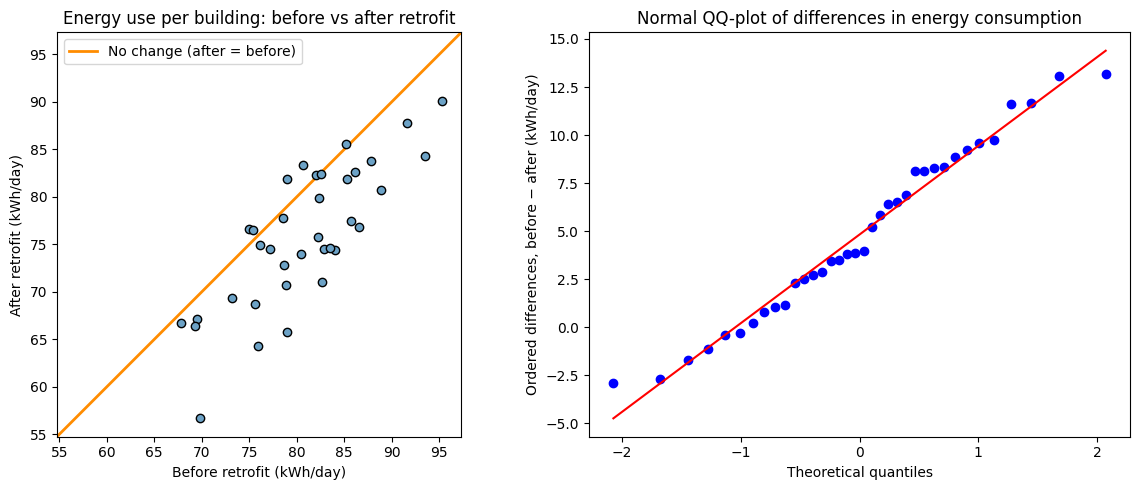

Number of buildings with savings: 30
Number of buildings without savings: 6


In [23]:
# Kristian
# Paired plot (left) and QQ-plot of the differences (right)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

before = energyRetrofitData["before_kwh_day"]
after = energyRetrofitData["after_kwh_day"]

# Left: before vs after, one point per building
axes[0].scatter(before, after, color="#6CA2C6", edgecolor="black", zorder=3)
lims = [min(before.min(), after.min()) - 2, max(before.max(), after.max()) + 2]
axes[0].plot(lims, lims, color="#FF8C00", lw=2, label="No change (after = before)")
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set_aspect("equal")
axes[0].set_title("Energy use per building: before vs after retrofit")
axes[0].set_xlabel("Before retrofit (kWh/day)")
axes[0].set_ylabel("After retrofit (kWh/day)")
axes[0].legend()

# Right: normal QQ-plot of the differences D = before - after
probplot(d, dist="norm", plot=axes[1])
axes[1].set_title("Normal QQ-plot of differences in energy consumption")
axes[1].set_xlabel("Theoretical quantiles")
axes[1].set_ylabel("Ordered differences, before − after (kWh/day)")

plt.tight_layout()
plt.show()

print(f"Number of buildings with savings: {(d > 0).sum()}")
print(f"Number of buildings without savings: {(d < 0).sum()}")

**Findings from the scatterplot:** For 30/36 buildings, their energy consumption was higher before the retrofit. This is seen as the dots that lie below the orange 'No Change' line. The 6/36 buildings that show higher energy consumption than before lie marginally above the no-change line, showing that in these cases there was a slight **increase** in energy consumption.

**Findings from the Normal QQ-plot:** All values trend closely along the normal line (red line). There is a slight tail at both ends, lower tail upwards and upper tail showing downwards - which shows that the tails are slightly shorter than normal - which is harmless. A clear outward bend (i.e. lower tail below the line, upper tail above the line) would indicate heavier tails than normal and would have been a concern. While there is slight wiggle along the line, no systematic curvature or clear outliers can be observed. This indicates that the difference values are approximately normally distributed.

**Overall:** As described in the course book (ch. 8.3., p. 126), for a paired problem, the differences are considered a one-sample problem. This means that we can apply Theorem 7.2 (The One-Sample t statistic under Null hypothesis), which applied to our study here, means that $D_i$ must be independent and identically distributed (i.i.d) from a normal population with mean $\mu_D$ and unknown variance. The plots show that the differences $D_i$ are approximately normally distributed. $D_i$ is considered i.i.d as described in the study design. This supports using the paired $t$-procedure, which is "often reasonably robust to moderate non-normality" (Course book, ch. 7.3., p. 113).

<br><br>
### 3.3 Test $H_0:\mu_D=0$ against a two-sided alternative and construct a 95% interval for $\mu_D$, using `ttest_rel` or an equivalent one-sample procedure applied to the differences.
Authored by: Kristian

Continuing with the 6-step analysis order presented in this assignment, we determine the 95% interval for $\mu_D$ in step 4, and define and test the hypothesis in step 5.

#### Step 4: Effect estimate and confidence interval.
**Effect:** The effect is estimated at $\bar{d} = 4.82$ kWh/day, which estimates the parameter $\mu_D$ (See 3.1 and 3.2).

**Confidence Interval:**
From Theorem 8.2 (Course book chapter 8.3, p. 127), we have the formula for a $(100(1 - \alpha))$% confidence interval for $\mu_D$ defined as:
$$\bar{d} \pm t_{n-1,\, 1-\alpha/2} \frac{s_D}{\sqrt{n}}.$$


We have already determined $\bar{d}$, $\alpha$, $s_D$ and $n$.

We still need to determine $t_{n-1, 1-\alpha/2}$. Since this value (n - 1 = 35), is not easily readable from our t-score table, we'll use scipy to compute this before computing the confidence interval using the formula above.
<br>

In [24]:
# Kristian
a_energy_consumption = 0.05
t_diff_critical_95 = t.ppf(1-(a_energy_consumption/2), df=(n_energy_consumption - 1))
print(f"t_diff_critical_95 = {t_diff_critical_95:.4f}\n")

ci_energy_consumption_lo = d_bar - (t_diff_critical_95 * (s_d / np.sqrt(n_energy_consumption)))
ci_energy_consumption_hi = d_bar + (t_diff_critical_95 * (s_d / np.sqrt(n_energy_consumption)))
print(f"95% confidence interval is                                [{ci_energy_consumption_lo:.4f}, {ci_energy_consumption_hi:.4f}] kWh/day")

# Verifying the CI using standard library functions:
res_p = ttest_rel(energyRetrofitData["before_kwh_day"], energyRetrofitData["after_kwh_day"], alternative="two-sided")
verify_ci = res_p.confidence_interval(confidence_level=0.95)
print(f"\nVerification using ttest_rel of 95% CI for μ_D (kWh/day): ({verify_ci.low:.4f}, {verify_ci.high:.4f})")

t_diff_critical_95 = 2.0301

95% confidence interval is                                [3.2990, 6.3466] kWh/day

Verification using ttest_rel of 95% CI for μ_D (kWh/day): (3.2990, 6.3466)


We see that the 95% confidence interval for $\mu_D$ is $[3.299, 6.347]$. This means that the plausible values for the mean energy consumptions reduction after retrofit, under the recorded conditions, are between 3.3 kWh/day and 6.35 kWh/day. The 95% refers to the procedure: under repeated sampling, about 95% of intervals constructed this way would contain $\mu_D$.

<br>

#### Step 5. Hypotheses, statistic, $p$-value, and decision.

##### Hypothesis
Since we wish to identify whether the control-system retrofit changed energy use, and by how much, we define a two-sided hypothesis:

$H_0 : \mu_D = 0$

$H_1 : \mu_D \neq 0$

Here $H_0$ states that the mean difference in energy consumption $\mu_D$ of the population of retrofitted buildings is unchanged after the retrofit, while $H_1$ states that it changed. This concerns our population parameter $\mu_D$, not the sample.

<br>

##### Test statistic
This is the paired t value, i.e. $t_{obs}$.

This value will be calculated below, using the formula from theorem 8.2:

$$t_{\mathrm{obs}} = \frac{\bar{d} - \Delta_0}{s_D / \sqrt{n}}, \text{with n - 1 degrees of freedom.}$$

Under $H_0$, $\Delta_0 = 0$, since we're testing the hypothesis where there is no change before and after the control-system retrofit.

<br>

In [25]:
t_diff_observed = (d_bar - 0) / (s_d / np.sqrt(n_energy_consumption))
print(f"t_diff_observed = {t_diff_observed:.4f}")

# Verifying using scipy's builtin library function
print(f"\nVerification using ttest_rel of t_obs = {res_p.statistic:.4f}, df = {res_p.df}, p-value = {res_p.pvalue}")

t_diff_observed = 6.4252

Verification using ttest_rel of t_obs = 6.4252, df = 35, p-value = 2.1350220863103607e-07


We find that the test **statistic (paired t-value)** is observed to be $6.425$.

##### p-value
If the retrofit had no effect on mean energy use ($\mu_D = 0$) and the assumptions hold, the probability ($p$-value) of a $t$ statistic at least as far from 0 as $|t_{obs}| = 6.425$ is $p = P(|T| \geq 6.425) = 0.0000002135022086310364$, as computed with scipy's ttest_rel function above.

<br>

##### Decision
Since p-value $\leq \alpha$ we reject $H_0$. This is derived by the **standard decision rule** in chapter 7.2 in the course book.

$0.0000002135022086310364 \leq 0.05$ is true

<br>

Since we rejected $H_0$ this means that the data provides evidence that the mean energy consumption of the buildings changed after the retrofit, and based on the confidence interval this points towards a mean reduction in energy consumption.

We will conclude further on these findings as part of 3.4.

<br><br>
### 3.4 Explain why an independent-samples test would discard useful pairing. Interpret the estimated reduction and interval in kWh/day and state a practical recommendation.
Authored by: Kristian

Continuing with the 6-step analysis order presented in this assignment, we now conclude.

#### Step 6. Practical importance, limitations, and conclusion.
The estimated mean reduction is $4.82$ kWh/day ($\bar d$), with a 95% CI of [3.30, 6.35] kWh/day. For a single building, the potential energy consumption savings on a yearly basis would then be between $3.299 \cdot 365 \approx 1,204$ and $6.347 \cdot 365 \approx 2,317$ kWh/year, with an average of $4.82 \cdot 365 \approx 1,760$ kWh/year. Assuming a fixed yearly price plan of 2.62 DKK per kWh and that the collected sample contains daily mean energy consumption based on an entire year, a retrofit could potentially reduce yearly expenses to energy for a building by an average of $1,760 \cdot 2.62 \approx 4,611$ DKK, and plausibly between $1,204 \cdot 2.62 \approx 3,155$ DKK and $2,317 \cdot 2.62 \approx 6,070$ DKK.

This conclusion is limited by the conditions under which the before and after energy consumptions were collected, and bounded by the assumptions made in 3.1. If, for example, the building energy consumptions before retrofit were collected from colder months/days and the energy consumption after were collected from warmer period (or with a reduced heating use due to various circumstances, such as maintenance, lower occupancy, etc.) the basic assumptions for this statistical analysis falls apart. Another major shortcoming in the study design is the lack of a control group - i.e. a portion of the buildings should receive the retro-fit and another portion should not, so that it would be possible to evaluate how much the changes between each recording period were affected by exterior circumstances, and thus the observed reduction cannot be attributed solely to the retrofit.

**Recommendation**: Perform the control-system retrofit on buildings under the same conditions, assumptions and limitations as those in the collected data and conclusion above. But also consider the price of the control-system retrofit itself and whether the potential savings shown above are reasonable compared to the price of performing the control-system retrofit.

<br>

#### Why would an independent-samples test discard useful pairing?
As described in the course book chapter 8.3. (p. 128), an independent two-sample analysis "estimates variability from separate groups and ignores within-pair association", and when applied to genuinely paired data "it can discard the precision gained through pairing".

In our study each building is measured twice, so the before and after values are not two independent groups, but 36 genuine pairs (see 3.1). The buildings differ a lot in their baseline energy consumption, and a building with a high consumption before the retrofit also tends to have a high consumption after - which is supported by the scatter plot in 3.2. Pairing removes this unit-to-unit baseline variation "because each unit acts as its own comparison" (Course book, p. 127).

To show what would be lost, we'll run Welch's two-sample $t$ procedure on the same data, treating before and after as if they were two independent groups. This is done for comparison only, since the independence assumption of Welch's procedure is violated here (the same building appears in both groups).

In [162]:
# All of this code is AI generated - adjusted and reviewed by Kristian:
res_w = ttest_ind(before, after, equal_var=False, alternative="two-sided")
se_welch = np.sqrt(before.var() / n_energy_consumption + after.var() / n_energy_consumption)
se_paired = s_d / np.sqrt(n_energy_consumption)

print(f"SD before               : {before.std():.4f},\nSD after                : {after.std():.4f},\ncorrelation r           : {before.corr(after):.4f},")
print(f"SE paired               : {se_paired:.4f},\nSE Welch                : {se_welch:.4f}\n")
print(f"Welch t statistic       : {res_w.statistic:.4f},\nWelch degrees of freedom: {res_w.df:.4f},\nWelch p-value           : {res_w.pvalue},\nWelch 95% CI {res_w.confidence_interval(confidence_level=0.95)}")

SD before               : 6.6336,
SD after                : 7.3530,
correlation r           : 0.7974,
SE paired               : 0.7506,
SE Welch                : 1.6505

Welch t statistic       : 2.9220,
Welch degrees of freedom: 69.2707,
Welch p-value           : 0.004693239075686424,
Welch 95% CI ConfidenceInterval(low=np.float64(1.5303072634501675), high=np.float64(8.115248292105408))


Running Welch's procedure gives $t_{obs} = 2.922$ with $69.27$ degrees of freedom, $p = 0.004693239075686424$ and a 95% CI of [1.53, 8.12] kWh/day.

The Welch procedure computes its standard error from the spread between the buildings in each group ($s_{before} = 6.63$ and $s_{after} = 7.35$ kWh/day):
$$SE_{Welch} = \sqrt{\frac{6.63^2}{36} + \frac{7.35^2}{36}} \approx 1.65 \text{ kWh/day}.$$

The paired procedure instead uses the spread of the differences, $s_D = 4.50$ kWh/day (see 3.1), giving $SE = 4.50 / \sqrt{36} \approx 0.75$ kWh/day.

From the course book (chapter 8.3., p. 127), the variance of a difference is $Var(D) = \sigma_X^2 + \sigma_Y^2 - 2\rho \cdot \sigma_X \cdot \sigma_Y,$ where $\rho$ is the population correlation.
Using the sample estimates $s_{before} = 6.63$, $s_{after} = 7.35$ and the sample correlation $r = 0.80$ in place of $\sigma_X$, $\sigma_Y$ and $\rho$, we get
$s_D^2 = s_{before}^2 + s_{after}^2 - 2r\,s_{before}\,s_{after} \approx 98.1 - 77.8 = 20.3 \approx 4.50^2.$

As is written in the course book, chapter 8.3., p. 127: "When the paired measurements are positively correlated, the final term reduces the variability of the differences"

<br>

**Overall:** Ignoring the pairing makes the standard error about 2.2 times larger (1.65 vs. 0.75 kWh/day) and the 95% confidence interval more than twice as wide (6.58 vs. 3.05 kWh/day). An independent-samples test would therefore discard useful information and give a much less precise estimate of the retrofit's effect.

<br><br><br>

---

<br>

## Part 4: Comparing two independent proportions

Two independently assigned software configurations were evaluated using separate requests. Configuration A had 38 SLA failures among 300 requests; configuration B had 22 among 320. Define the risk difference as $p_A-p_B$.

<br><br>
### 4.1 State the observational unit, binary outcome, populations, assumptions, comparison order, and two-sided hypotheses.
Authored by: Kristian

<br>

Following the expected 6-step analysis order defined in the assignment brief.

#### Step 1: Question, parameter, units, and comparison order.
|                    |                                                                                                                                                    |
|:------------------:|:--------------------------------------------------------------------------------------------------------------------------------------------------:|
|      Question      |                               Does the two configurations differ in SLA-failure probability, and if so, by how much?                               |
| Observational Unit |                                                          A single request (of 300 + 320)                                                           |
|  Binary Outcomes   |           Failure: Request caused an SLA Failure (A: 38 and B: 22)<br/>Success: Request did NOT cause an SLA Failure (A: 262 and B: 298)           |
|     Population     | 2 populations, all requests handled by configuration A ($p_A$), and all requests handled by B ($p_B$),<br/>under the conditions they were recorded |
|     Parameter      |                        The risk difference $p_A - p_B$, where $p_A$ and $p_B$ are the **population** failure probabilities.                        |
|  Comparison order  |                                 Compare Configuration A against B (i.e. A - B),<br/>as described in part 4 above.                                  |
|       Units        |                                                Probabilities (the difference in percentage points)                                                 |

<br>

#### Step 2: Study design and assumptions.

Two independent samples are provided, Configuration A and Configuration B.

**Configuration A** contains 300 observational units, where each observational unit is a single software request, and the outcome whether the request violated the Software Service Level Agreement (SLA). Exactly what the violation/failure involves is not described in this question, so we assume the failure is related to SLA defined performance requirements (i.e. response time, or similar). 38 outcomes were failures/violations.

**Configuration B** contains 320 requests, of which 22 outcomes were failures/violations.

Based on the provided description, we assume that "independently assigned" and "separate requests" mean that:
1. Each request is completely independent of other requests
2. Within each configuration each request has the same failure probability ($p_A$ for A and $p_B$ for B).
3. Both configurations (samples) are completely independent of each other. The same requests don't appear in both of these.
4. That enough observations (including failures and successes) in both samples were made to make an accurate normal approximation.

**Significance Level**: We assume the failures are not critical for peoples lives or health, and as such we define a standard $\alpha = 0.05$.

<br>

#### Hypothesis
Even though the hypothesis should belong to step 5, we will state it here - as it is specifically requested in this task.
We build a null hypothesis assuming that the risk of failure is the same for both configurations, with an alternative hypothesis stating it is not.

$H_0 : p_A = p_B$

$H_1 : p_A \neq p_B$


<br><br>
### 4.2 Calculate both sample proportions, their difference in percentage points, and a 95% confidence interval using separate estimated variances.
Authored by: Kristian

<br>

#### Step 3: Descriptive summaries and plots.
To describe the 2 sample proportions, we'll calculate their failure proportions $\hat{p}$ using this formula (Course book chapter 8.4, p. 128):

$$\hat{p}_A = \frac{x_A}{n_A} \text{ and,   } \hat{p}_B = \frac{x_B}{n_B}$$

Their difference will then be determined using:
$$\hat{p}_A - \hat{p}_B = \text{risk difference}$$

In [27]:
# Kristian
n_a = 300
n_b = 320

x_a = 38
x_b = 22

phat_a = x_a / n_a
phat_b = x_b / n_b
phat_a_minus_b = phat_a - phat_b

print(f"phat_a          = {phat_a:.4f}")
print(f"phat_b          = {phat_b:.4f}")
print(f"phat_a - phat_b = {phat_a_minus_b:.4f}")


phat_a          = 0.1267
phat_b          = 0.0688
phat_a - phat_b = 0.0579


#### Step 4: Effect estimate and confidence interval.

The observed failure proportions are

$\hat{p}_A = 0.1267 = 12.67\%$ and $\hat{p}_B = 0.0688 = 6.88\%$

Thus,

$\hat{\Delta}_P = \hat{p}_A - \hat{p}_B = 0.0579 = 5.79 \text{ percentage points}$

In practice, this means that Configuration A had 5.79 more SLA failures per 100 requests than Configuration B.

<br>

The estimated standard error for the two proportions can be calculated using the formulae below (Course Book, chapter 8.4, p. 128)

$$\mathrm{SE}(\hat{p}_A - \hat{p}_B) = \sqrt{\frac{\hat{p}_A(1 - \hat{p}_A)}{n_A} + \frac{\hat{p}_B(1 - \hat{p}_B)}{n_B}}.$$

From that an approximate $100(1 - \alpha)$% interval for $p_A - p_B$ is thus defined as:

$$(\hat{p}_A - \hat{p}_B) \pm z_{1-\alpha/2} \, \mathrm{SE}(\hat{p}_A - \hat{p}_B).$$

Since we're interested in the 95% interval (i.e. alpha = 5%), we need a z-score for $z_{1-0.05/2} = z_{0.975}$ from our z-score table we can determine that $z_{0.975} = 1.960$

In [28]:
SE_A_minus_B = np.sqrt((phat_a * (1 - phat_a) / n_a) + (phat_b * (1 - phat_b) / n_b))
print(f"Standard Error, A - B = {SE_A_minus_B}")

A_minus_B_95_conf_interval_lo = phat_a_minus_b - 1.960 * SE_A_minus_B
A_minus_B_95_conf_interval_hi = phat_a_minus_b + 1.960 * SE_A_minus_B

print(f"95% confidence interval = [{A_minus_B_95_conf_interval_lo:.4f} : {A_minus_B_95_conf_interval_hi:.4f}]")

Standard Error, A - B = 0.023849821444368105
95% confidence interval = [0.0112 : 0.1047]


**Effect and Confidence Interval:** We find that the estimated risk difference is $\hat{p}_A - \hat{p}_B = 5.79$ percentage points with a 95% confidence interval of $[1.1, 10.5]$ percentage points. Practically this means that Configuration A is estimated to have between 1.1 and 10.5 percentage points more SLA failures than B, under the conditions that the data was observed. Since 0 is not included in the interval, this provides evidence towards configuration A failing more often than configuration B, with anywhere from about 1 to 10 failures more per 100 requests.

<br><br>
### 4.3 Test $H_0:p_A=p_B$ with a two-proportion $z$ procedure. Report $z$, the two-sided $p$-value, decision, and contextual conclusion.

Authored by: Katrine

#### Step 5. Hypotheses, statistic, $p$-value, and decision.

##### Hypotheses
As stated in 4.1, we test $H_0: p_A = p_B$ against the two-sided $H_1: p_A \neq p_B$ at $\alpha = 0.05$.

##### Test statistic
The test is calculated under the assumption that $H_0$ is true. If $p_A = p_B$, both configurations share one common failure probability, which we estimate by pooling all requests:

$$\hat{p} = \frac{x_A + x_B}{n_A + n_B}$$

The standard error under $H_0$ then uses this pooled proportion for both groups:

$$SE_0 = \sqrt{\hat{p}(1 - \hat{p})\left(\frac{1}{n_A} + \frac{1}{n_B}\right)}$$

and the test statistic is

$$z = \frac{\hat{p}_A - \hat{p}_B}{SE_0}$$

which is approximately standard normal under $H_0$ when the expected counts are large enough. This standard error differs from the one used for the confidence interval in 4.2. The interval does not assume $H_0$, so it uses separate estimated variances for the two groups.

In [31]:
# Two-proportion z test of H0: p_A = p_B, using the pooled proportion under H0
phat_pooled = (x_a + x_b) / (n_a + n_b)
se_0 = np.sqrt(phat_pooled * (1 - phat_pooled) * (1 / n_a + 1 / n_b))

z_obs = (phat_a_minus_b - 0) / se_0
p_value_z = 2 * norm.sf(abs(z_obs))
print(f"Manual:      pooled proportion = {phat_pooled:.4f}, SE_0 = {se_0:.4f}, z = {z_obs:.3f}, p = {p_value_z:.4f}")

# Verification with statsmodels (uses the pooled proportion by default)
z_check, p_check = proportions_ztest(count=[x_a, x_b], nobs=[n_a, n_b])
print(f"statsmodels: z = {z_check:.3f}, p = {p_check:.4f}")

# Normal approximation check: expected counts under H0 should be at least about 10
print(f"Expected failures:     A = {n_a * phat_pooled:.1f}, B = {n_b * phat_pooled:.1f}")
print(f"Expected non-failures: A = {n_a * (1 - phat_pooled):.1f}, B = {n_b * (1 - phat_pooled):.1f}")

Manual:      pooled proportion = 0.0968, SE_0 = 0.0238, z = 2.438, p = 0.0148
statsmodels: z = 2.438, p = 0.0148
Expected failures:     A = 29.0, B = 31.0
Expected non-failures: A = 271.0, B = 289.0


##### Results
Pooled proportion: $\hat{p} = 60/620 = 0.0968$.

Normal approximation: Under $H_0$, the expected numbers of failures are 29.0 (A) and 31.0 (B), and the expected numbers of non-failures are 271.0 (A) and 289.0 (B). All are well above 10, so the normal approximation is adequate.

Test statistic: $SE_0 = 0.0238$ and $z = 0.0579 / 0.0238 = 2.438$. The observed difference is about 2.4 times larger than its standard error under $H_0$.

p-value: The two-sided $p$-value is $p = 0.0148$. If both configurations had the same failure probability and the assumptions hold, a test statistic at least as far from 0 as 2.438, in either direction, would occur in about 1.5% of repeated samples.

The manual calculation and statsmodels' `proportions_ztest` give the same results.

##### Decision and conclusion
Since $p = 0.0148 \leq \alpha = 0.05$, we reject $H_0$. The data provide evidence that the SLA failure probability differs between the two configurations, with configuration A failing more often than B. The estimated risk difference is 5.79 percentage points, and the 95% interval from 4.2, $[1.1,\ 10.5]$ percentage points, also excludes 0. The test and the interval agree here, but they use different standard errors (pooled vs. separate), so their agreement is not guaranteed in general. Whether the difference is caused by the configuration is discussed in 4.4.

<br><br>
### 4.4 State what random sampling and random assignment would each support and why a significant difference alone is not enough for an unrestricted causal claim.

Authored by: Katrine

#### Step 6. Limitations and causal interpretation.

##### Random sampling
Random sampling means that the requests are selected at random from the population of all requests that the configurations would handle. It supports generalisation: the estimated difference can then be applied to that whole population, and not only to the 620 requests in the study. The task does not state how the requests were selected, so the results apply to requests like those observed, under the conditions in which they were recorded.

##### Random assignment
Random assignment means that chance, for example random routing, decides which configuration handles each request. It supports a causal interpretation: other factors, such as request size, network conditions or time of day, are then spread evenly across the two groups on average, so the configuration is the only systematic difference between them. The task describes the configurations as "independently assigned", but it does not state whether the requests were randomly assigned to them.

##### Why a significant difference is not enough
The test in 4.3 shows that the difference in failure rates is unlikely to be caused by random variation alone. It does not show why the difference exists. If configuration A had received larger requests, worse network conditions or more traffic at peak hours, these factors could explain part or all of the difference. A causal claim requires random assignment, and even then it only applies to the population and conditions covered by the study. A significant difference alone therefore does not support an unrestricted claim that configuration A causes more SLA failures.

<br><br><br>

---

<br>

## Part 5: AI-Use and Conclusion
### AI-use
> State which AI tools you used, what they contributed, what you changed or rejected, and how you verified the final work. A short paragraph or table is sufficient.

#### In part 1 - Claude Opus 5.5
`Assigned to: Katrine & Kristian`
- AI was used to help explain concepts and the overall analysis order and how this ties into the specific questions.
- AI was used to provide feedback on the manually drafted versions of task solutions.
- Assisted in resolving markdown properly syntax (latex)

##### What changed/got rejected:
- For 1.4, while I had initially conducted all the computations in a single code cell, the AI review highlighted that software results belong as part of step 5. Based on that i restructured the ordering of the analysis for this question.
- For 1.5 I was mixing 'percent (%)' and 'percentage point' such that some of the comments and explanations would read wrongly (i.e. 0.5% above the 5% target... which should be 0.5 percentage points above the 5% target). AI helped point these inconsistencies (and other such minor inconsistencies) out, so that I could fix these!

##### How we checked that the final work was correct:
- Compared to relevant sections from the course book (explanations and formulas), to ensure that AI based suggestions were rooted in the actual course literature.
<br><br>

#### In part 2 - [Clade Opus 5.5]
`Assigned to: Katrine`
- AI was used as a tutor to explain the concepts behind the tasks (independent vs. paired samples, Welch's procedure, confidence intervals, test–interval duality and practical importance), using examples from the course slides and interactive figures.
- AI guided the analysis through questions
- AI provided the plotting code and the code for Welch's procedure, which I ran and checked.

##### What changed/got rejected:
- Wording of the different textual sections, as well as improving readability for the latex.
- My first draft placed the 8-hour threshold in the research question. After feedback, the hypotheses were stated as two-sided about $\delta = 0$, and the threshold was moved to the practical-importance assessment in 2.4.
- My descriptions of the plots were corrected where I mixed up the median and the mean

##### How we checked that the final work was correct:
- My hand calculations of the standard error and $t$ were compared with the code output.
- The manual Welch calculation was compared with SciPy's `ttest_ind(..., equal_var=False)`.
- Methods and formulas were compared with the course slides and Brooks, Chapter 8.
<br><br>

#### In part 3 - Claude Opus 5.5
`Assigned to: Kristian`
- AI was used to provide feedback on the manually drafted versions of task solutions.
- Assisted in resolving markdown properly syntax (latex)

##### What changed/got rejected:
- AI generated the code for the plots.
- AI generated the code block used to exemplify the independent samples tests using welch, for comparison.

##### How we checked that the final work was correct:
- Compared to relevant sections from the course book (explanations and formulas), to ensure that AI based suggestions were rooted in the actual course literature.
- Used built-in functions to verify manual computations, where relevant.
<br><br>

#### In part 4 - Claude Opus 5.5
`Assigned to: Kristian & Katrine`
- AI was used to provide feedback on the manually drafted versions of task solutions.
- Assisted in resolving markdown properly syntax (latex)

##### What changed/got rejected:
- Its explanation of what an SLA is in the context of the part 4 question caused the term "Service Level Agreement" to frame the study design in 4.1.
- Many typos got fixed, statements made more clear.

##### How we checked that the final work was correct:
- Compared to relevant sections from the course book (explanations and formulas), to ensure that AI based suggestions were rooted in the actual course literature.
<br><br>

_____________

### Overall conclusion
> Write approximately 150–250 words comparing what the four designs allow you to conclude. Include effects and intervals, not only decisions, and distinguish statistical significance, practical importance, and causal interpretation.
>
> Only use Sessions 7–8. Do not use ANOVA, regression, or chi-square methods.

**Part 1:**
In the sensor study, the mean calibration error was 0.188 °C (95% CI $[0.032,\ 0.345]$ °C, $t(63) = 2.407$, $p = 0.019$). The bias is statistically significant but practically small, since the whole interval lies within ±0.50 °C.

In the false-rejection study, 20/240 attempts were falsely rejected under test conditions ($\hat p = 0.083$). A one-sided exact binomial test against the 5% threshold gave $p$-value $= 0.018$, rejecting $H_0$ at $\alpha = 0.05$. The 95% wilson interval $[0.055, 0.125]$ indicated a false-rejection excess rate of 0.5-7.5 percentage points.

**Part 2:**
The modified coating lasted an estimated 15.2 h longer than the standard coating (95% CI $[7.27,\ 23.13]$ h, Welch $p = 0.00026$). The difference is statistically significant and probably practically important, but the interval dips just below the 8-hour threshold. Since random assignment of specimens is not described, a causal effect of the process is not established.

**Part 3:** For 36 buildings measured before and after a retrofit, the mean reduction was $\bar d = 4.82$ kWh/day, 95% CI $[3.30, 6.35]$, rejecting $H_0: \mu_D = 0$ ($p = 0.0000002135022086310364$). That is about 1,200–2,300 kWh of potential savings per building per year.

**Part 4:**
Configuration A failed 38 of 300 requests ($\hat p_A = 0.127$) and B 22 of 320 ($\hat p_B = 0.069$), a risk difference of 5.79 percentage points, 95% CI $[1.1, 10.5]$. Under the conditions the data was collected, A plausibly fails about 1–10 more times per 100 requests than B.

**Across the designs:** All three studies point away from the null value, but significance does not show practical importance: whether 0.5–7.5 extra false rejections per 100 attempts, 1,200–2,300 kWh saved per building per year, or 1–10 extra SLA failures per 100 requests matter depends on context. Other factors than the change itself could explain the differences, since none of the studies had a fair comparison group chosen at random.

## Submission Checklist

- [ ] Every hypothesis concerns a clearly defined population parameter.
- [ ] Test direction and comparison order are fixed before results.
- [ ] $p$-values are interpreted conditionally on $H_0$ and assumptions.
- [ ] “Fail to reject” is not described as proof of $H_0$.
- [ ] Welch is the default for independent means and genuine pairs are analysed as differences.
- [ ] Proportion interval and test standard errors are not interchanged.
- [ ] Effects and confidence intervals are reported in engineering units.
- [ ] Part 5 contains AI-use and conclusion.
- [ ] All code is executed and output is visible.